# Random Forest Classifier untuk EcoPlant AI

Klasifikasi penyakit daun pisang dari citra RGB menggunakan dataset `training/OriginalSet`. Notebook mempertahankan alur yang sama dengan notebook KNN: preprocessing citra, ekstraksi histogram warna 48 fitur, split stratifikasi 80:20 dengan `random_state=42`, lalu evaluasi. Model ini adalah Random Forest classifier, bukan regresi.

## 0. Persiapan dan lokasi dataset

Jalankan notebook di Jupyter/VS Code dari root proyek yang memiliki folder `training/OriginalSet`.

Jika menggunakan **Google Colab** dan dataset berada di Google Drive, jalankan terlebih dahulu:

```python
from google.colab import drive
drive.mount('/content/drive')
```

Kemudian isi `DATA_DIR_OVERRIDE` dengan **path folder `OriginalSet` yang sebenarnya** di Drive. Kosongkan jika notebook dijalankan dari root proyek. Jangan menyertakan file ZIP mentah sebagai path dataset; ekstrak dahulu.

> Tidak perlu memakai GPU untuk latihan Random Forest berbasis 48 fitur ini.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)

RANDOM_STATE = 42
IMAGE_SIZE = (64, 64)
BINS_PER_CHANNEL = 16
DATA_DIR_OVERRIDE = ""  # Isi lokasi OriginalSet jika tidak berada di root proyek.

if DATA_DIR_OVERRIDE.strip():
    DATA_DIR = Path(DATA_DIR_OVERRIDE).expanduser()
else:
    DATA_DIR = next(
        (p / "training" / "OriginalSet" for p in [Path.cwd(), *Path.cwd().parents]
         if (p / "training" / "OriginalSet").is_dir()),
        None,
    )

if DATA_DIR is None or not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Folder training/OriginalSet belum ditemukan. "
        "Letakkan notebook di root proyek atau isi DATA_DIR_OVERRIDE "
        "dengan path folder OriginalSet yang sudah diekstrak."
    )

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_files = {}
for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        class_files.setdefault(path.parent.name, []).append(path)

# Sama seperti notebook KNN: label diambil dari folder paling dekat dengan file gambar.
class_names = sorted(class_files)
image_paths = [
    path for name in class_names for path in sorted(class_files[name])
]
labels = [
    label for label, name in enumerate(class_names)
    for _ in sorted(class_files[name])
]

if len(class_names) < 2 or len(image_paths) < 4:
    raise ValueError("Dataset kurang dari dua kelas atau jumlah gambar terlalu sedikit.")

print("Sumber dataset:", DATA_DIR)
print("Nama kelas:", class_names)
print("Jumlah file per kelas:", {k: len(v) for k, v in class_files.items()})
print("Jumlah file ditemukan:", len(image_paths))

expected_classes = {"cordana", "healthy", "pestalotiopsis", "sigatoka"}
if set(name.lower() for name in class_names) != expected_classes:
    print("PERINGATAN: kelas tidak sama dengan empat kelas yang dilaporkan kelompok.")
    print("Periksa apakah ada folder gambar tambahan atau nama folder tidak konsisten.")

Sumber dataset: c:\PBL-KEL4_TI3C_SEM5\training\OriginalSet
Nama kelas: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka']
Jumlah file per kelas: {'cordana': 262, 'healthy': 236, 'pestalotiopsis': 290, 'sigatoka': 573}
Jumlah file ditemukan: 1361


## 1. Pra-pemrosesan gambar

Sama seperti notebook KNN: setiap gambar dibaca sebagai RGB, di-*resize* menjadi **64 × 64**, lalu intensitas piksel diskalakan ke **0–1**. File yang tidak dapat dibuka akan dilewati.

In [2]:
preprocessed_images, valid_paths, valid_labels = [], [], []
for path, label in zip(image_paths, labels):
    try:
        with Image.open(path) as img:
            pixels = np.asarray(
                img.convert("RGB").resize(IMAGE_SIZE), dtype=np.float32
            ) / 255.0
        preprocessed_images.append(pixels)
        valid_paths.append(path)
        valid_labels.append(label)
    except (OSError, ValueError) as err:
        print(f"Lewati gambar bermasalah: {path} | {err}")

image_paths = valid_paths
y = np.asarray(valid_labels, dtype=int)
if len(preprocessed_images) == 0:
    raise ValueError("Tidak ada gambar valid yang bisa diproses.")

print("Jumlah citra valid:", len(preprocessed_images))
print("Rentang intensitas piksel:",
      min(float(im.min()) for im in preprocessed_images), "sampai",
      max(float(im.max()) for im in preprocessed_images))
print("Distribusi kelas:")
print(pd.Series(y).map(lambda i: class_names[i]).value_counts().reindex(class_names))

c:\PBL-KEL4_TI3C_SEM5\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
c:\PBL-KEL4_TI3C_SEM5\.venv\Lib\site-packages\PIL\JpegImagePlugin.py:874: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Jumlah citra valid: 1361
Rentang intensitas piksel: 0.0 sampai 1.0
Distribusi kelas:
cordana           262
healthy           236
pestalotiopsis    290
sigatoka          573
Name: count, dtype: int64


## 2. Ekstraksi fitur histogram warna RGB

Persis mengikuti notebook KNN: setiap kanal R, G, B dibuat histogram dengan 16 bin pada rentang 0–1, menggunakan `density=True`. Setiap gambar diwakili **48 angka**.

**Catatan:** Histogram warna tidak menyimpan posisi bercak/lesi pada daun, sehingga performa model bisa terbatas.

In [3]:
features = []
for pixels in preprocessed_images:
    histogram_48 = np.concatenate([
        np.histogram(pixels[:, :, ch], bins=BINS_PER_CHANNEL,
                     range=(0, 1), density=True)[0]
        for ch in range(3)
    ])
    features.append(histogram_48)

X = np.asarray(features)
feature_names = [
    f"{channel}_bin_{b:02d}"
    for channel in ("R", "G", "B")
    for b in range(1, BINS_PER_CHANNEL + 1)
]

print("Bentuk matriks X:", X.shape)
print("Bentuk target y:", y.shape)
assert X.shape[1] == 48, "Fitur tidak berjumlah 48. Periksa metode histogram."
assert np.isfinite(X).all(), "Ada fitur tak terhingga atau NaN dari ekstraksi."

Bentuk matriks X: (1361, 48)
Bentuk target y: (1361,)


## 3. Pembagian data latih dan uji (80:20)

Menggunakan **indeks data yang sama cara pengacakannya dengan KNN** agar perbandingan lebih sejalan. Rasio kelas dijaga memakai `stratify=y`.

> **Keterbatasan yang perlu disampaikan pada laporan:** pembagian per gambar belum memastikan foto dari daun/tanaman yang sama tidak masuk ke train dan test sekaligus. Jika tersedia identitas daun/tanaman, evaluasi lanjutan sebaiknya menggunakan *group split* dan pemeriksaan duplikasi.

In [4]:
train_indices, test_indices = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("\nDistribusi data uji:")
print(pd.Series(y_test).map(lambda i: class_names[i]).value_counts().reindex(class_names))

Data latih: (1088, 48) | Data uji: (273, 48)

Distribusi data uji:
cordana            53
healthy            47
pestalotiopsis     58
sigatoka          115
Name: count, dtype: int64


## 4. Training model Random Forest

Random Forest menggabungkan banyak pohon keputusan. Konfigurasi awal berikut memakai:

- `n_estimators=200` — 200 pohon keputusan.
- `random_state=42` — hasil lebih mudah direproduksi.
- `class_weight='balanced'` — pembobotan karena jumlah gambar per kelas tidak sama.
- `n_jobs=-1` — gunakan inti CPU yang tersedia.
- `SimpleImputer(strategy='median')` dalam pipeline — statistik dari data latih saja.

**Mengapa tidak memakai `StandardScaler`?** Decision tree / Random Forest tidak memerlukan standardisasi seperti KNN; pemisahan pohon bergantung pada batas nilai fitur, bukan jarak Euclidean.

In [5]:
rf_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    ),
)

rf_pipeline.fit(X_train, y_train)
y_pred = rf_pipeline.predict(X_test)

print("Training Random Forest selesai.")
print("Jumlah pohon:", rf_pipeline.named_steps["randomforestclassifier"].n_estimators)

Training Random Forest selesai.
Jumlah pohon: 200


## 5. Evaluasi model

Gunakan **accuracy, precision macro, recall macro, dan F1-score macro**, seperti tabel evaluasi laporan kelompok. Untuk dataset yang tidak seimbang, **F1 macro** penting karena memberi bobot yang sama pada setiap kelas.

In [6]:
accuracy = accuracy_score(y_test, y_pred)
prec_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=np.arange(len(class_names)),
    average="macro", zero_division=0
)

summary = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy (%)": round(accuracy * 100, 2),
    "Precision (macro)": round(prec_macro, 4),
    "Recall (macro)": round(recall_macro, 4),
    "F1-score (macro)": round(f1_macro, 4),
}])
print(summary.to_string(index=False))
print("\nClassification report per kelas:")
print(classification_report(
    y_test, y_pred, labels=np.arange(len(class_names)),
    target_names=class_names, zero_division=0,
))

        Model  Accuracy (%)  Precision (macro)  Recall (macro)  F1-score (macro)
Random Forest         80.95             0.7926          0.8157            0.8005

Classification report per kelas:
                precision    recall  f1-score   support

       cordana       0.78      0.85      0.81        53
       healthy       0.80      0.87      0.84        47
pestalotiopsis       0.63      0.74      0.68        58
      sigatoka       0.96      0.80      0.87       115

      accuracy                           0.81       273
     macro avg       0.79      0.82      0.80       273
  weighted avg       0.83      0.81      0.81       273



## 6. Confusion matrix

Baris = kelas **aktual**. Kolom = kelas **prediksi**. Angka diagonal adalah prediksi yang benar. Simpan gambarnya agar bisa dipakai untuk laporan UTS.

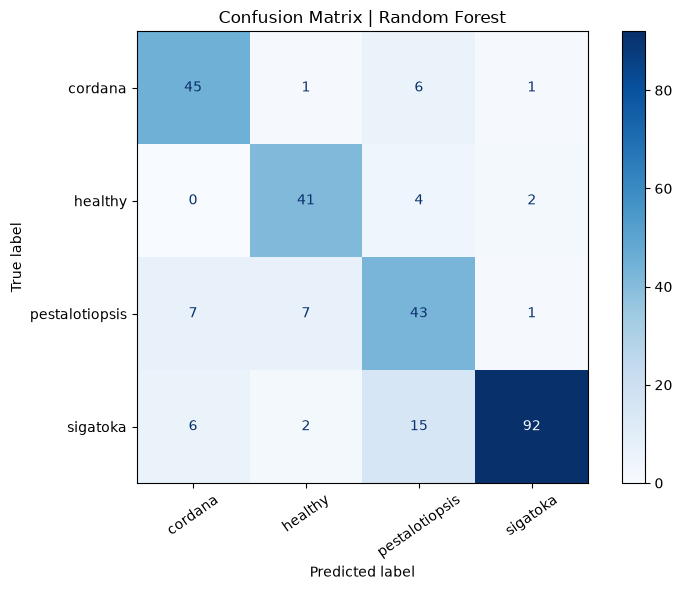

Grafik tersimpan: rf_confusion_matrix.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=np.arange(len(class_names)),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=35,
    ax=ax,
    colorbar=True,
)
ax.set_title("Confusion Matrix | Random Forest")
fig.tight_layout()
fig.savefig("rf_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()
print("Grafik tersimpan: rf_confusion_matrix.png")

## 7. Kontribusi fitur (opsional untuk pembahasan)

Grafik berikut menunjukkan fitur histogram mana yang paling sering membantu pemisahan pada pohon. **Feature importance bukan bukti sebab-akibat** atau bukti bahwa suatu penyakit ditentukan oleh satu warna tertentu.

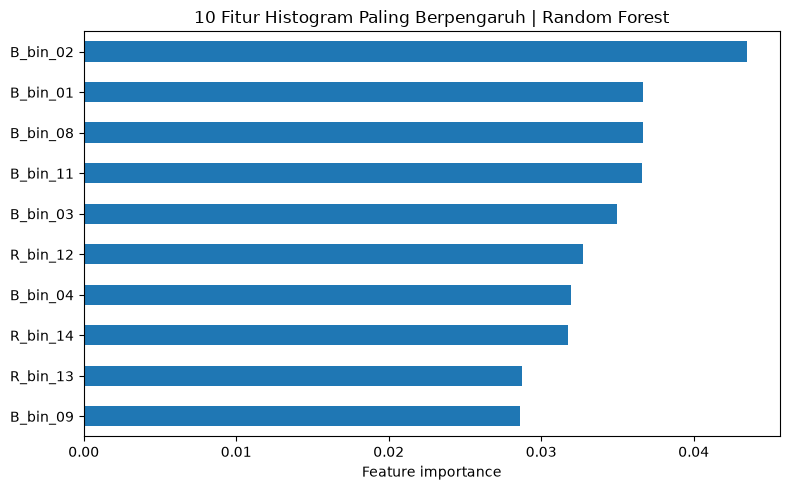

Grafik tersimpan: rf_feature_importance.png


In [8]:
rf = rf_pipeline.named_steps["randomforestclassifier"]
importance = pd.Series(rf.feature_importances_, index=feature_names)
top10 = importance.sort_values(ascending=False).head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
top10.plot(kind="barh", ax=ax)
ax.set_xlabel("Feature importance")
ax.set_title("10 Fitur Histogram Paling Berpengaruh | Random Forest")
fig.tight_layout()
fig.savefig("rf_feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()
print("Grafik tersimpan: rf_feature_importance.png")

## 8. Contoh prediksi satu gambar pada data uji

Contoh ini menggunakan **gambar dari data uji** dan fitur yang sudah diekstrak, bukan gambar baru di luar dataset. Skor `predict_proba` merupakan keluaran model dan **belum tentu probabilitas yang terkalibrasi**.

File: c:\PBL-KEL4_TI3C_SEM5\training\OriginalSet\sigatoka\341.jpeg
Kelas aktual: sigatoka
Prediksi Random Forest: sigatoka
Skor model per kelas:
cordana           0.015
healthy           0.010
pestalotiopsis    0.010
sigatoka          0.965
dtype: float64


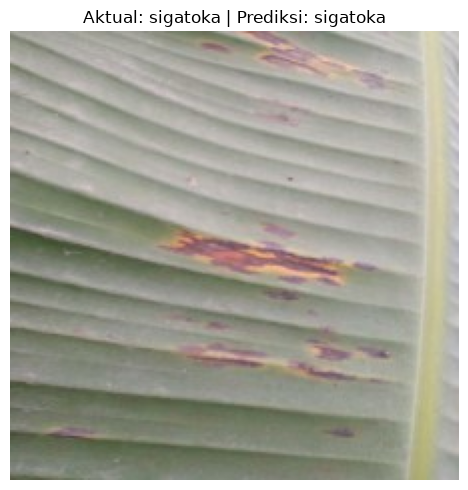

In [9]:
sample_index = 0
sample_path = image_paths[int(test_indices[sample_index])]
sample_pred = int(rf_pipeline.predict(X_test[[sample_index]])[0])
sample_proba = rf_pipeline.predict_proba(X_test[[sample_index]])[0]

print("File:", sample_path)
print("Kelas aktual:", class_names[int(y_test[sample_index])])
print("Prediksi Random Forest:", class_names[sample_pred])
print("Skor model per kelas:")
print(pd.Series(sample_proba, index=class_names).round(4))

with Image.open(sample_path) as img:
    plt.figure(figsize=(5, 5))
    plt.imshow(img.convert("RGB"))
    plt.axis("off")
    plt.title(f"Aktual: {class_names[int(y_test[sample_index])]} | Prediksi: {class_names[sample_pred]}")
    plt.tight_layout()
    plt.show()

## 9. Simpan model dan hasil evaluasi

File `.joblib` menyimpan pipeline Python (imputer + Random Forest). File ini **tidak dapat langsung menggantikan `model.tflite` di Flutter**. Untuk mengintegrasikan Random Forest ke aplikasi, perlu layanan Python/API atau metode konversi dan implementasi yang memang kompatibel, dengan ekstraksi histogram yang konsisten.

**Keamanan:** hanya *load* file `.joblib` dari sumber yang tepercaya.

In [10]:
joblib.dump(rf_pipeline, "ecoplant_random_forest.joblib")
summary.to_csv("rf_evaluation_summary.csv", index=False)

metadata = {
    "nama_model": "Random Forest Classifier",
    "jenis_fitur": "RGB histogram: 16 bins x 3 channels = 48 fitur",
    "ukuran_gambar": list(IMAGE_SIZE),
    "urutan_kelas": class_names,
    "random_state": RANDOM_STATE,
    "rasio_test": 0.20,
    "n_estimators": 200,
    "class_weight": "balanced",
    "jumlah_data_valid": len(y),
    "akurasi_test": float(accuracy),
    "f1_macro_test": float(f1_macro),
}
with open("ecoplant_random_forest_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

results = pd.DataFrame({
    "nama_file": [str(image_paths[int(i)]) for i in test_indices],
    "aktual": [class_names[int(v)] for v in y_test],
    "prediksi": [class_names[int(v)] for v in y_pred],
})
results.to_csv("rf_test_predictions.csv", index=False)

print("File tersimpan:")
for filename in [
    "ecoplant_random_forest.joblib",
    "ecoplant_random_forest_metadata.json",
    "rf_evaluation_summary.csv",
    "rf_test_predictions.csv",
    "rf_confusion_matrix.png",
    "rf_feature_importance.png",
]:
    print("-", Path(filename).resolve())

File tersimpan:
- C:\PBL-KEL4_TI3C_SEM5\UTS PBL ML\Model ML\ecoplant_random_forest.joblib
- C:\PBL-KEL4_TI3C_SEM5\UTS PBL ML\Model ML\ecoplant_random_forest_metadata.json
- C:\PBL-KEL4_TI3C_SEM5\UTS PBL ML\Model ML\rf_evaluation_summary.csv
- C:\PBL-KEL4_TI3C_SEM5\UTS PBL ML\Model ML\rf_test_predictions.csv
- C:\PBL-KEL4_TI3C_SEM5\UTS PBL ML\Model ML\rf_confusion_matrix.png
- C:\PBL-KEL4_TI3C_SEM5\UTS PBL ML\Model ML\rf_feature_importance.png


## 10. Perbandingan hasil model

Nilai KNN, Naive Bayes, dan SVM berasal dari eksekusi notebook masing-masing pada dataset dan split yang sama (stratified 80:20, random_state=42). Random Forest dilatih pada split dengan konfigurasi identik. Tetap perhatikan bahwa evaluasi dilakukan per gambar, belum per kelompok daun/sumber.

In [11]:
comparison = pd.DataFrame([
    {"Model": "KNN (Afrizal)", "Accuracy (%)": 71.43, "F1-score macro": 0.6739},
    {"Model": "Naive Bayes (Andi)", "Accuracy (%)": 54.58, "F1-score macro": 0.5024},
    {"Model": "Random Forest (Siti)", "Accuracy (%)": round(accuracy * 100, 2), "F1-score macro": round(f1_macro, 4)},
    {"Model": "SVM RBF (Fattah)", "Accuracy (%)": 75.46, "F1-score macro": 0.7291},
])
print(comparison.to_string(index=False))

               Model  Accuracy (%)  F1-score macro
       KNN (Afrizal)         71.43          0.6739
  Naive Bayes (Andi)         54.58          0.5024
Random Forest (Siti)         80.95          0.8005
    SVM RBF (Fattah)         75.46          0.7291


## 11. Interpretasi singkat untuk laporan

- **Tujuan:** melakukan klasifikasi empat kelas kondisi daun pisang menggunakan Random Forest.
- **Input:** citra RGB 64 × 64 yang diubah menjadi fitur histogram RGB 48 dimensi.
- **Data:** `training/OriginalSet`, dengan rasio latih-uji 80:20 secara stratifikasi (`random_state=42`).
- **Model:** Random Forest dengan 200 pohon dan `class_weight='balanced'`.
- **Evaluasi:** laporkan akurasi, precision macro, recall macro, F1 macro, dan confusion matrix **sesuai keluaran aktual notebook**.
- **Keterbatasan:** histogram warna tidak mengukur letak lesi; data bisa berisi foto serupa antara train-test; perlu validasi pada gambar baru dan kondisi lapangan.

> Untuk integrasi Flutter EcoPlant AI, jangan memasukkan file `.joblib` langsung sebagai `.tflite`; mekanisme inferensinya berbeda.